# 📊 Exploratory Data Analysis (EDA): Data Penjualan & Data Bahan Baku

**Mitra UMKM:** Ale's Place Cipoho — Tim Capstone `A26-CS218` (*Stok Makanan Sudah Habis*)  
**Bidang:** Data Science Specialist (Afdha Auliya Atiq & Hauzan Ziyadatul Khoir)  
**Periode Data Penjualan:** `01 Oktober 2025` s.d. `31 Oktober 2026` (**396** hari kalender, **395** hari operasional aktif)  
**Sumber Data:** `ales_place_dwh.db` *(13 bulan laporan kasir NutaCloud + Master Bahan Baku & Resep BoM 2018)*

---

### 🔎 Pertanyaan Bisnis yang Ingin Dijawab
1. **Pola Trafik Penjualan:** Bagaimana pola penjualan per hari (*Senin–Minggu*), perbandingan *Weekday* vs *Weekend*, dan jam tersibuk (*peak hours*)?
2. **Tren Musiman & Tanggal Gajian:** Bagaimana tren bulanan sepanjang Okt 2025 – Okt 2026, seberapa besar lonjakan Ramadhan, dan apakah periode gajian (*payday window*) memengaruhi omzet?
3. **Perilaku Pelanggan & Channel:** *Channel* apa yang paling dominan dan memiliki rata-rata nilai belanja (*Average Order Value / AOV*) tertinggi?
4. **Menu Terlaris & Celah Resep:** Menu dan kategori kasir apa yang paling laku, serta menu terlaris mana saja yang belum tercakup master resep 2018?
5. **Karakteristik & Konsumsi Bahan Baku:** Bagaimana profil vendor/satuan bahan baku, bahan apa yang paling cepat habis (*Daily Burn Rate*) dan paling melonjak di akhir pekan, serta seberapa besar konsumsi internal (`CREW`/`OWNER`) memotong stok dapur?

In [1]:
from pathlib import Path
import sqlite3
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.edgecolor"] = "#CBD5E1"
plt.rcParams["axes.linewidth"] = 0.8

# Deteksi path DWH secara portabel dari folder notebooks/
cwd = Path.cwd().resolve()
if (cwd.parent / "scripts").exists() and cwd.name == "notebooks":
    WORKSPACE_DIR = cwd.parents[2]
elif (cwd / "tugas_mingguan").exists():
    WORKSPACE_DIR = cwd
else:
    WORKSPACE_DIR = Path(r"D:\0. Dokumen Kuliah\Semester 5\0. Project Capstone")

DWH_PATH = WORKSPACE_DIR / "tugas_mingguan" / "minggu-1" / "output" / "data_penjualan" / "ales_place_dwh.db"
assert DWH_PATH.exists(), f"Database tidak ditemukan: {DWH_PATH}"

with sqlite3.connect(DWH_PATH) as conn:
    df_tx = pd.read_sql("SELECT * FROM fact_transaksi", conn)
    df_items = pd.read_sql("SELECT * FROM fact_penjualan_item", conn)
    df_map = pd.read_sql("SELECT * FROM map_menu_kasir", conn)
    df_bahan = pd.read_sql("SELECT * FROM dim_bahan_baku", conn)
    df_menu = pd.read_sql("SELECT * FROM dim_menu", conn)
    df_kat = pd.read_sql("SELECT * FROM dim_kategori_menu", conn)
    df_bom = pd.read_sql("SELECT * FROM fact_resep_bom", conn)
    df_usage = pd.read_sql("SELECT * FROM v_pemakaian_bahan_harian", conn)

print(f"fact_transaksi          : {df_tx.shape}")
print(f"fact_penjualan_item     : {df_items.shape}")
print(f"map_menu_kasir          : {df_map.shape}")
print(f"dim_bahan_baku          : {df_bahan.shape}")
print(f"dim_menu                : {df_menu.shape}")
print(f"fact_resep_bom          : {df_bom.shape}")
print(f"v_pemakaian_bahan_harian: {df_usage.shape}")

fact_transaksi          : (9295, 28)
fact_penjualan_item     : (49240, 17)
map_menu_kasir          : (381, 7)
dim_bahan_baku          : (178, 11)
dim_menu                : (135, 8)
fact_resep_bom          : (1579, 6)
v_pemakaian_bahan_harian: (38754, 6)


## 1. Gambaran Umum & Kualitas Data Penjualan
Kita periksa kelengkapan data transaksi, rentang tanggal kalender, hari toko tutup, proporsi transaksi eksternal vs internal, serta total omzet kotor/bersih.

In [2]:
null_counts = df_tx[["id_transaksi", "tanggal", "jam", "channel_penjualan", "metode_pembayaran", "grand_total", "is_internal_order"]].isna().sum()
print("Missing value pada kolom kunci transaksi:")
print(null_counts.to_string())

full_calendar = pd.date_range("2025-10-01", "2026-10-31", freq="D").strftime("%Y-%m-%d")
active_days = sorted(df_tx["tanggal"].unique())
closed_days = sorted(set(full_calendar) - set(active_days))

ext_tx = df_tx[df_tx["is_internal_order"] == 0]
int_tx = df_tx[df_tx["is_internal_order"] == 1]
void_lines = int((df_items["qty"] <= 0).sum())
disc_lines = int((df_items["is_diskon_item"] == 1).sum())
split_tx = int((df_tx["is_split_payment"] == 1).sum())

print(f"\nRentang tanggal  : {df_tx['tanggal'].min()} s.d. {df_tx['tanggal'].max()} ({len(full_calendar)} hari kalender)")
print(f"Hari aktif / tutup: {len(active_days)} hari aktif | Tutup: {closed_days}")
print(f"Total transaksi  : {len(df_tx):,} (Eksternal: {len(ext_tx):,}, Internal: {len(int_tx):,})")
print(f"Total grand_total: Rp {df_tx['grand_total'].sum():,.0f} (Eksternal: Rp {ext_tx['grand_total'].sum():,.0f})")
print(f"Total porsi net  : {df_items['qty'].sum():,.0f} porsi/item | Split payment: {split_tx:,} | Diskon item: {disc_lines:,} | Baris void: {void_lines}")

Missing value pada kolom kunci transaksi:
id_transaksi         0
tanggal              0
jam                  0
channel_penjualan    0
metode_pembayaran    0
grand_total          0
is_internal_order    0

Rentang tanggal  : 2025-10-01 s.d. 2026-10-31 (396 hari kalender)
Hari aktif / tutup: 395 hari aktif | Tutup: ['2026-03-21']
Total transaksi  : 9,295 (Eksternal: 8,508, Internal: 787)
Total grand_total: Rp 1,479,571,300 (Eksternal: Rp 1,443,778,300)
Total porsi net  : 58,102 porsi/item | Split payment: 175 | Diskon item: 792 | Baris void: 4


## 2. Insight Data Penjualan: Pola Hari (*Senin–Minggu*), *Weekday* vs *Weekend*, & Jam Tersibuk
Bagian ini mencari pola ritme harian dan jam operasional dapur untuk melihat kapan lonjakan beban pesanan paling tinggi.

Rata-rata harian per Hari (Senin - Minggu):
nama_hari  tx_cnt      omzet
    Senin   17.75 2626373.21
   Selasa   17.96 2550357.14
     Rabu   19.39 2777124.56
    Kamis   17.84 2676692.98
    Jumat   20.63 3043694.73
    Sabtu   34.14 6267467.86
   Minggu   37.23 6327464.29

Rata-rata Weekday vs Weekend:
                   tx_cnt       omzet
segmen_hari                          
Weekday (Sen-Kam)   18.24  2658250.00
Weekend (Jum-Min)   30.61  5200040.23

Top 5 Jam Tersibuk:
jam
20    1374
19    1239
18    1198
17     971
15     889


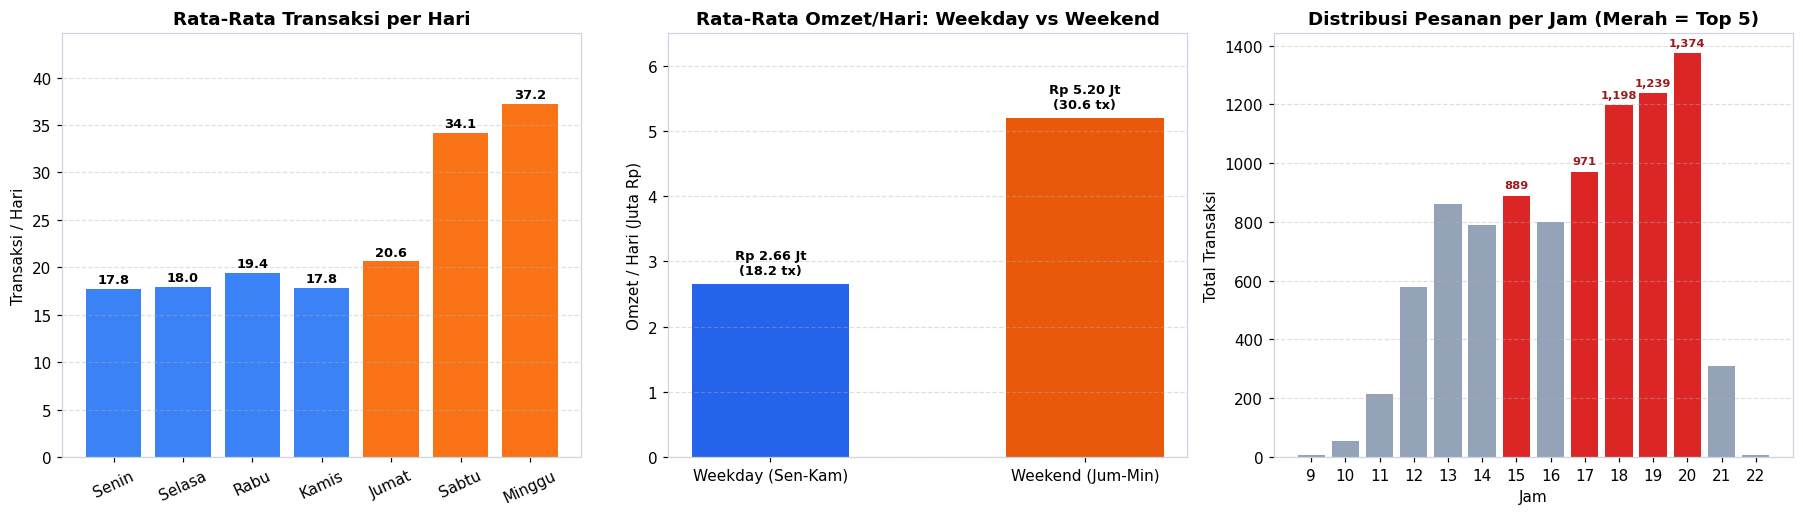

In [3]:
df_tx["dt"] = pd.to_datetime(df_tx["tanggal"])
df_tx["dow"] = df_tx["dt"].dt.dayofweek
day_names = {0: "Senin", 1: "Selasa", 2: "Rabu", 3: "Kamis", 4: "Jumat", 5: "Sabtu", 6: "Minggu"}
df_tx["nama_hari"] = df_tx["dow"].map(day_names)
df_tx["segmen_hari"] = np.where(df_tx["dow"].isin([4, 5, 6]), "Weekend (Jum-Min)", "Weekday (Sen-Kam)")

daily_stat = df_tx.groupby(["tanggal", "dow", "nama_hari", "segmen_hari"], as_index=False).agg(
    tx_cnt=("id_transaksi", "count"),
    omzet=("grand_total", "sum"),
)

by_dow = daily_stat.groupby(["dow", "nama_hari"], as_index=False)[["tx_cnt", "omzet"]].mean().sort_values("dow")
by_seg = daily_stat.groupby("segmen_hari")[["tx_cnt", "omzet"]].mean().round(2)
hourly = df_tx["jam"].value_counts().sort_index()

print("Rata-rata harian per Hari (Senin - Minggu):")
print(by_dow[["nama_hari", "tx_cnt", "omzet"]].round(2).to_string(index=False))
print("\nRata-rata Weekday vs Weekend:")
print(by_seg.to_string())
print("\nTop 5 Jam Tersibuk:")
print(df_tx["jam"].value_counts().head(5).to_string())

fig, axes = plt.subplots(1, 3, figsize=(16.5, 4.8))

# Plot 1: Rata-rata transaksi per hari Senin-Minggu
colors_dow = ["#3B82F6" if d < 4 else "#F97316" for d in by_dow["dow"]]
b1 = axes[0].bar(by_dow["nama_hari"], by_dow["tx_cnt"], color=colors_dow)
axes[0].set_title("Rata-Rata Transaksi per Hari", fontweight="bold")
axes[0].set_ylabel("Transaksi / Hari")
axes[0].set_ylim(0, by_dow["tx_cnt"].max() * 1.2)
axes[0].tick_params(axis="x", rotation=25)
axes[0].grid(axis="y", linestyle="--", alpha=0.4)
for b in b1:
    axes[0].text(b.get_x() + b.get_width()/2, b.get_height() + 0.6, f"{b.get_height():.1f}", ha="center", fontsize=8.5, fontweight="bold")

# Plot 2: Weekday vs Weekend omzet harian
seg_order = ["Weekday (Sen-Kam)", "Weekend (Jum-Min)"]
seg_omzet_jt = [by_seg.loc[s, "omzet"] / 1e6 for s in seg_order]
b2 = axes[1].bar(seg_order, seg_omzet_jt, color=["#2563EB", "#EA580C"], width=0.5)
axes[1].set_title("Rata-Rata Omzet/Hari: Weekday vs Weekend", fontweight="bold")
axes[1].set_ylabel("Omzet / Hari (Juta Rp)")
axes[1].set_ylim(0, max(seg_omzet_jt) * 1.25)
axes[1].grid(axis="y", linestyle="--", alpha=0.4)
for b, s in zip(b2, seg_order):
    axes[1].text(b.get_x() + b.get_width()/2, b.get_height() + 0.15, f"Rp {b.get_height():.2f} Jt\n({by_seg.loc[s, 'tx_cnt']:.1f} tx)", ha="center", fontsize=8.5, fontweight="bold")

# Plot 3: Distribusi transaksi per jam
top5_h = set(df_tx["jam"].value_counts().head(5).index)
h_colors = ["#DC2626" if h in top5_h else "#94A3B8" for h in hourly.index]
axes[2].bar(hourly.index.astype(str), hourly.values, color=h_colors)
axes[2].set_title("Distribusi Pesanan per Jam (Merah = Top 5)", fontweight="bold")
axes[2].set_xlabel("Jam")
axes[2].set_ylabel("Total Transaksi")
axes[2].grid(axis="y", linestyle="--", alpha=0.4)
for idx, (h, v) in enumerate(zip(hourly.index, hourly.values)):
    if h in top5_h:
        axes[2].text(idx, v + 25, f"{v:,}", ha="center", fontsize=7.5, fontweight="bold", color="#991B1B")

plt.tight_layout()
plt.show()

## 3. Insight Data Penjualan: Tren Bulanan, Lonjakan Ramadhan, & Efek Payday
Melihat apakah omzet resto bersifat stabil sepanjang tahun atau memiliki puncak musiman tertentu serta menguji apakah tanggal gajian (`tgl 25 – tgl 5`) menaikkan omzet harian.

Tren Bulanan (Okt 2025 - Okt 2026):
  bulan   tx       omzet      aov
2025-10  747 108031000.0 144620.0
2025-11  790 107424500.0 135980.0
2025-12  881 140571500.0 159559.0
2026-01  813 136779500.0 168240.0
2026-02  694 105296500.0 151724.0
2026-03 1112 214614500.0 192999.0
2026-04  724 108734000.0 150185.0
2026-05  705 109083400.0 154728.0
2026-06  721 108349100.0 150276.0
2026-07  579  89113700.0 153910.0
2026-08  583  83899500.0 143910.0
2026-09  446  73214000.0 164157.0
2026-10  500  94460100.0 188920.0

Perbandingan Rata-Rata Harian Payday vs Non-Payday:
                    tx_cnt       omzet
is_payday                             
Payday (Tgl 25-5)    24.26  3820956.38
Reguler (Tgl 6-24)   23.09  3700198.37


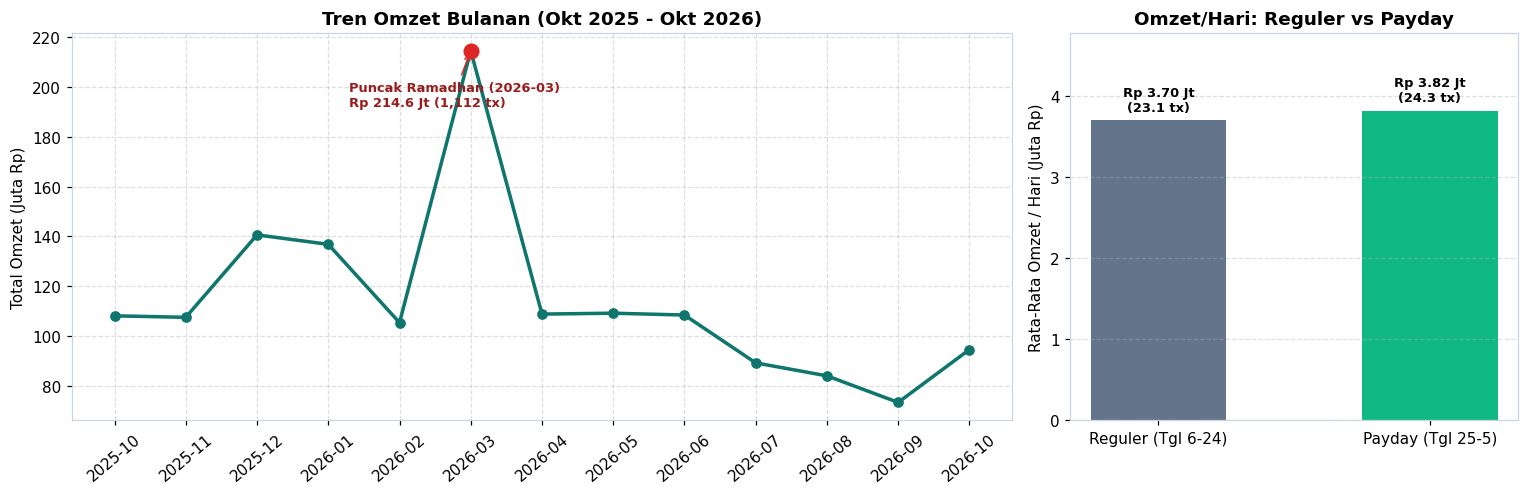

In [4]:
df_tx["bulan"] = df_tx["tanggal"].str.slice(0, 7)
monthly = df_tx.groupby("bulan", as_index=False).agg(
    tx=("id_transaksi", "count"),
    omzet=("grand_total", "sum"),
    aov=("grand_total", "mean"),
).sort_values("bulan")

daily_stat["is_payday"] = np.where((pd.to_datetime(daily_stat["tanggal"]).dt.day >= 25) | (pd.to_datetime(daily_stat["tanggal"]).dt.day <= 5), "Payday (Tgl 25-5)", "Reguler (Tgl 6-24)")
payday_stat = daily_stat.groupby("is_payday")[["tx_cnt", "omzet"]].mean().round(2)

print("Tren Bulanan (Okt 2025 - Okt 2026):")
print(monthly.round(0).to_string(index=False))
print("\nPerbandingan Rata-Rata Harian Payday vs Non-Payday:")
print(payday_stat.to_string())

fig, axes = plt.subplots(1, 2, figsize=(14, 4.6), gridspec_kw={"width_ratios": [2.1, 1]})

axes[0].plot(monthly["bulan"], monthly["omzet"] / 1e6, marker="o", linewidth=2.3, color="#0F766E", label="Omzet Bulanan (Juta Rp)")
peak_i = int(monthly["omzet"].idxmax())
peak_r = monthly.loc[peak_i]
axes[0].scatter([peak_r["bulan"]], [peak_r["omzet"] / 1e6], color="#DC2626", s=90, zorder=5)
axes[0].annotate(
    f"Puncak Ramadhan ({peak_r['bulan']})\nRp {peak_r['omzet']/1e6:.1f} Jt ({int(peak_r['tx']):,} tx)",
    xy=(peak_r["bulan"], peak_r["omzet"] / 1e6),
    xytext=(-80, -36),
    textcoords="offset points",
    arrowprops=dict(arrowstyle="->", color="#DC2626"),
    fontsize=8.5, fontweight="bold", color="#991B1B",
)
axes[0].set_title("Tren Omzet Bulanan (Okt 2025 - Okt 2026)", fontweight="bold")
axes[0].set_ylabel("Total Omzet (Juta Rp)")
axes[0].tick_params(axis="x", rotation=40)
axes[0].grid(True, linestyle="--", alpha=0.4)

p_order = ["Reguler (Tgl 6-24)", "Payday (Tgl 25-5)"]
p_vals = [payday_stat.loc[p, "omzet"] / 1e6 for p in p_order]
bp = axes[1].bar(p_order, p_vals, color=["#64748B", "#10B981"], width=0.5)
axes[1].set_title("Omzet/Hari: Reguler vs Payday", fontweight="bold")
axes[1].set_ylabel("Rata-Rata Omzet / Hari (Juta Rp)")
axes[1].set_ylim(0, max(p_vals) * 1.25)
axes[1].grid(axis="y", linestyle="--", alpha=0.4)
for b, p in zip(bp, p_order):
    axes[1].text(b.get_x() + b.get_width()/2, b.get_height() + 0.12, f"Rp {b.get_height():.2f} Jt\n({payday_stat.loc[p, 'tx_cnt']:.1f} tx)", ha="center", fontsize=8.5, fontweight="bold")

plt.tight_layout()
plt.show()

## 4. Insight Data Penjualan: Channel Penjualan, Rata-Rata Nilai Struk (*AOV*), & Brand Store
Mengetahui kontribusi transaksi tiap kanal pemesanan (`Dine-In`, `Takeaway`, Ojol) dan ukuran rata-rata belanja (*Average Order Value*) per struk.

Statistik Channel Penjualan:
channel_penjualan  transaksi        omzet      aov  share_tx_pct
          Dine-In       8286 1375492100.0 166002.0          89.0
         Takeaway        422   34618000.0  82033.0           5.0
         GrabFood        265   26432400.0  99745.0           3.0
       ShopeeFood        225   27899000.0 123996.0           2.0
           GoFood         87    9444800.0 108561.0           1.0
            Event         10    5685000.0 568500.0           0.0

Kontribusi Brand Store:
brand_store   tx        omzet
Ale's Place 9280 1478430300.0
   Risoldut   15    1141000.0


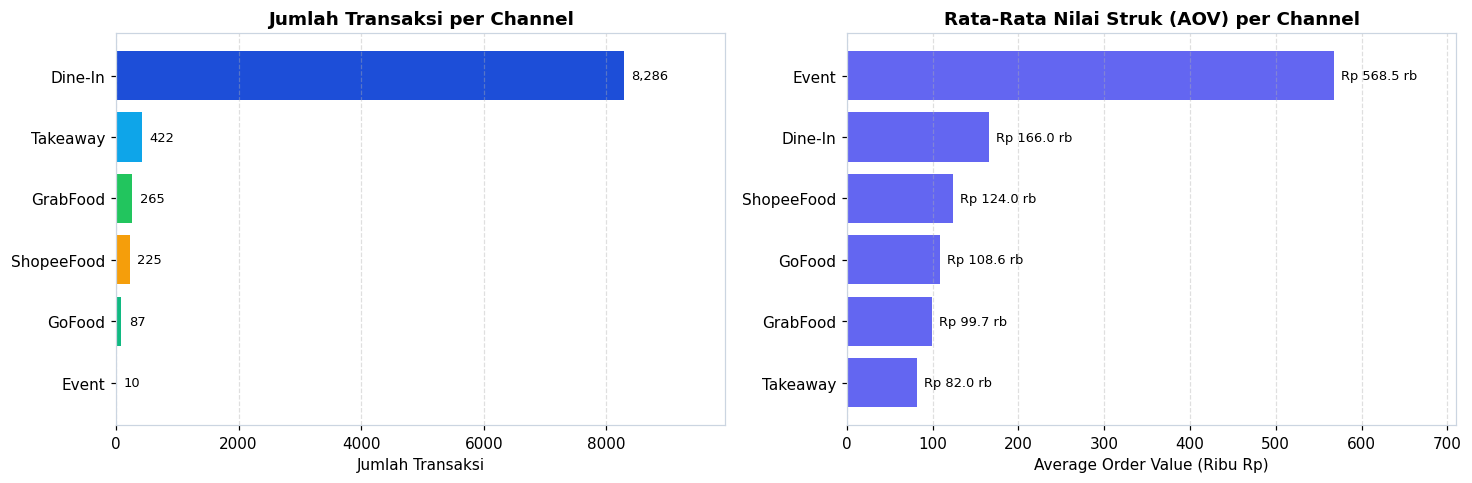

In [5]:
ch_stat = (
    df_tx.groupby("channel_penjualan", as_index=False)
    .agg(
        transaksi=("id_transaksi", "count"),
        omzet=("grand_total", "sum"),
        aov=("grand_total", "mean"),
    )
    .sort_values("transaksi", ascending=False)
)
ch_stat["share_tx_pct"] = (ch_stat["transaksi"] / ch_stat["transaksi"].sum() * 100).round(2)
print("Statistik Channel Penjualan:")
print(ch_stat.round(0).to_string(index=False))

brand_stat = df_tx.groupby("brand_store", as_index=False).agg(tx=("id_transaksi", "count"), omzet=("grand_total", "sum"))
print("\nKontribusi Brand Store:")
print(brand_stat.round(0).to_string(index=False))

ch_plot = ch_stat.sort_values("transaksi", ascending=True)
fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.5))

c_bars = axes[0].barh(ch_plot["channel_penjualan"], ch_plot["transaksi"], color=["#94A3B8", "#10B981", "#F59E0B", "#22C55E", "#0EA5E9", "#1D4ED8"][:len(ch_plot)])
axes[0].set_title("Jumlah Transaksi per Channel", fontweight="bold")
axes[0].set_xlabel("Jumlah Transaksi")
axes[0].set_xlim(0, ch_plot["transaksi"].max() * 1.2)
axes[0].grid(axis="x", linestyle="--", alpha=0.4)
for b in c_bars:
    axes[0].text(b.get_width() + 120, b.get_y() + b.get_height()/2, f"{int(b.get_width()):,}", va="center", fontsize=8.5)

ch_aov = ch_stat.sort_values("aov", ascending=True)
a_bars = axes[1].barh(ch_aov["channel_penjualan"], ch_aov["aov"] / 1e3, color="#6366F1")
axes[1].set_title("Rata-Rata Nilai Struk (AOV) per Channel", fontweight="bold")
axes[1].set_xlabel("Average Order Value (Ribu Rp)")
axes[1].set_xlim(0, (ch_aov["aov"].max() / 1e3) * 1.25)
axes[1].grid(axis="x", linestyle="--", alpha=0.4)
for b in a_bars:
    axes[1].text(b.get_width() + 8, b.get_y() + b.get_height()/2, f"Rp {b.get_width():,.1f} rb", va="center", fontsize=8.5)

plt.tight_layout()
plt.show()

## 5. Insight Data Penjualan: Menu Terlaris, Kategori Terkuat, & Gap Resep BoM 2018
Menemukan menu apa yang paling menggerakkan penjualan sekaligus mengidentifikasi berapa banyak menu populer kasir (`2025–2026`) yang belum terhubung ke database resep 2018.

Top 10 Kategori Menu Kasir (berdasarkan porsi terjual):
                kategori_kasir  total_qty  total_omzet
                         Ramen      10354    330203800
                       Minuman       7640     85875000
                         Sushi       4738    144844450
       Mojito Smoothies Freeze       4089     94021000
                         Snack       4060     85513250
             Tako Oko Yakitori       3294     76622500
Pingku Ropang Pudding IC Scoop       3037     54357900
                      Hotplate       2675     85596000
                     Ala Carte       2071     12142750
                  Varian Juice       1754     35709000

Top 15 Menu Terlaris di Kasir (2025-2026):
           nama_item_kasir                 kategori_kasir  total_qty_terjual  total_omzet_net       status_resep
         Redhot Beef Ramen                          Ramen               2331         80984500 Terhubung BoM 2018
            Takoyaki Isi 6              Tako Oko Yakitori            

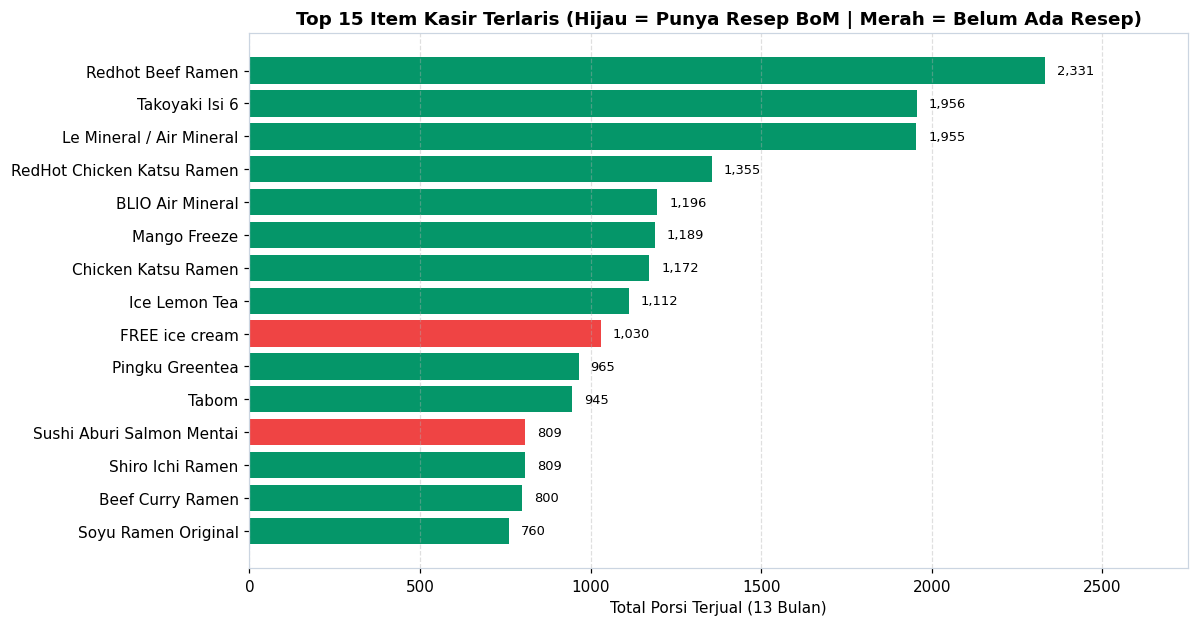

In [6]:
kat_kasir = (
    df_items.groupby("kategori_kasir", as_index=False)
    .agg(total_qty=("qty", "sum"), total_omzet=("subtotal_net", "sum"))
    .sort_values("total_qty", ascending=False)
)
print("Top 10 Kategori Menu Kasir (berdasarkan porsi terjual):")
print(kat_kasir.head(10).round(0).to_string(index=False))

top15_menu = df_map.sort_values("total_qty_terjual", ascending=False).head(15).copy()
top15_menu["status_resep"] = np.where(top15_menu["match_status"].isin(["MAPPED_EXACT", "MAPPED_ALIAS"]), "Terhubung BoM 2018", "Belum Ada Resep")
print("\nTop 15 Menu Terlaris di Kasir (2025-2026):")
print(top15_menu[["nama_item_kasir", "kategori_kasir", "total_qty_terjual", "total_omzet_net", "status_resep"]].to_string(index=False))

cov = df_map.groupby("match_status", as_index=False).agg(jml_menu=("nama_item_kasir", "count"), total_qty=("total_qty_terjual", "sum"))
cov["pct_qty"] = (cov["total_qty"] / cov["total_qty"].sum() * 100).round(1)
print("\nRingkasan Cakupan Pemetaan Menu Kasir <-> Resep BoM:")
print(cov.to_string(index=False))

m_plot = top15_menu.sort_values("total_qty_terjual", ascending=True)
m_colors = ["#059669" if s == "Terhubung BoM 2018" else "#EF4444" for s in m_plot["status_resep"]]
fig, ax = plt.subplots(figsize=(11, 5.8))
bm = ax.barh(m_plot["nama_item_kasir"], m_plot["total_qty_terjual"], color=m_colors)
ax.set_title("Top 15 Item Kasir Terlaris (Hijau = Punya Resep BoM | Merah = Belum Ada Resep)", fontweight="bold")
ax.set_xlabel("Total Porsi Terjual (13 Bulan)")
ax.set_xlim(0, m_plot["total_qty_terjual"].max() * 1.18)
ax.grid(axis="x", linestyle="--", alpha=0.4)
for b in bm:
    ax.text(b.get_width() + 35, b.get_y() + b.get_height()/2, f"{int(b.get_width()):,}", va="center", fontsize=8.5)

plt.tight_layout()
plt.show()

## 6. Insight Data Bahan Baku: Struktur Master Bahan, Vendor, & Menu HPP Tertinggi
Mengeksplorasi data master bahan baku (`dim_bahan_baku`) dan komposisi resep (`dim_menu` & `fact_resep_bom`) untuk memahami struktur biaya, satuan, dan supplier utama.

Distribusi Satuan Dasar (178 Bahan Baku):
satuan_dasar
gram    117
pcs      34
ml       27

Bahan Pangan (0) vs Kemasan/Utilitas (1):
is_packaging
Bahan Pangan        164
Kemasan/Utilitas     14

Top 8 Kategori Vendor Supplier:
kategori_vendor
TOKO HAI & FEI          75
SAYUR                   31
OM WEGA                 25
TOKO ACI                15
TAMBAHAN DARI RESEP     13
YOGYA SUPERINDO ALFA    12
SUPPLIER LAINNYA         5
MITRA DAGING             2

Top 10 Menu Resep 2018 dengan HPP Tertinggi per Porsi:
nama_kategori                   nama_menu  total_hpp_standar
     HOTPLATE    HP Nasi Blackpepper Sapi           16685.51
     HOTPLATE     HP Mie Blackpepper Sapi           16519.51
     HOTPLATE HP Kwetiaw Blackpepper Sapi           16319.51
     HOTPLATE HP Kwetiaw Blackpepper Ayam           15719.51
     HOTPLATE          HP Nasi Siram Sapi           15552.33
     HOTPLATE     HP Mie Blackpepper Ayam           15109.51
      DONBURI        Donburi Mozaru Katsu           15051

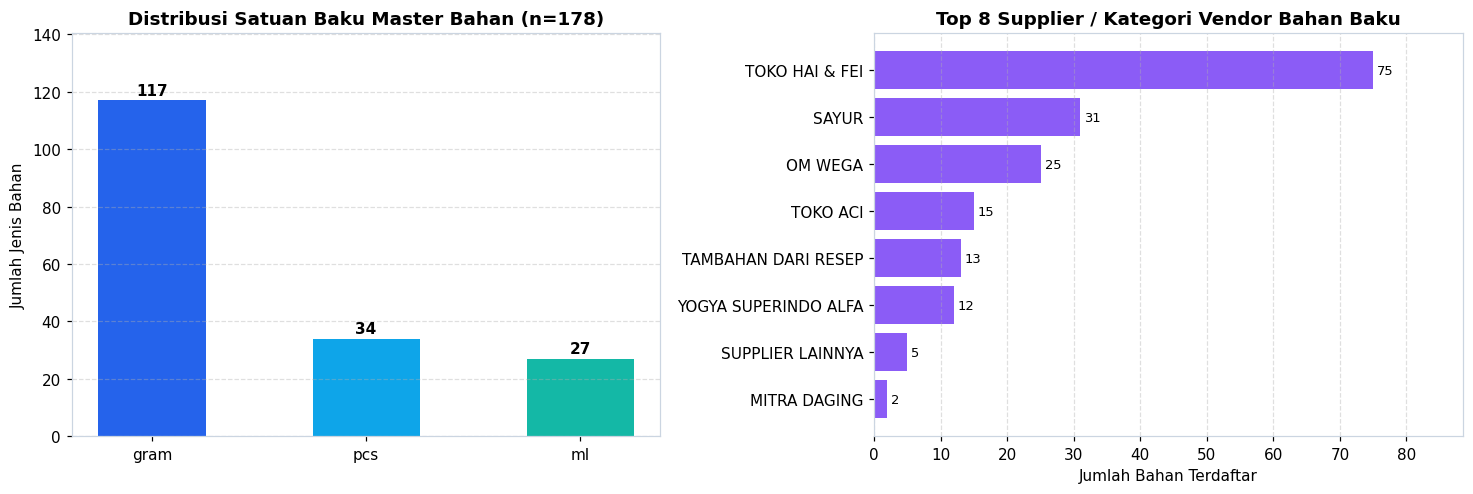

In [7]:
print("Distribusi Satuan Dasar (178 Bahan Baku):")
print(df_bahan["satuan_dasar"].value_counts().to_string())
print("\nBahan Pangan (0) vs Kemasan/Utilitas (1):")
print(df_bahan["is_packaging"].value_counts().rename(index={0: "Bahan Pangan", 1: "Kemasan/Utilitas"}).to_string())

vendor_cnt = df_bahan["kategori_vendor"].value_counts().head(8)
print("\nTop 8 Kategori Vendor Supplier:")
print(vendor_cnt.to_string())

sellable_menus = df_menu[df_menu["is_sellable"] == 1].merge(df_kat, on="id_kategori", how="left")
top_hpp_menu = sellable_menus.sort_values("total_hpp_standar", ascending=False).head(10)
print("\nTop 10 Menu Resep 2018 dengan HPP Tertinggi per Porsi:")
print(top_hpp_menu[["nama_kategori", "nama_menu", "total_hpp_standar"]].to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.6))
u_counts = df_bahan["satuan_dasar"].value_counts()
bu = axes[0].bar(u_counts.index, u_counts.values, color=["#2563EB", "#0EA5E9", "#14B8A6"], width=0.5)
axes[0].set_title("Distribusi Satuan Baku Master Bahan (n=178)", fontweight="bold")
axes[0].set_ylabel("Jumlah Jenis Bahan")
axes[0].set_ylim(0, u_counts.max() * 1.2)
axes[0].grid(axis="y", linestyle="--", alpha=0.4)
for b in bu:
    axes[0].text(b.get_x() + b.get_width()/2, b.get_height() + 2, f"{int(b.get_height())}", ha="center", fontweight="bold")

v_plot = vendor_cnt.sort_values(ascending=True)
bv = axes[1].barh(v_plot.index, v_plot.values, color="#8B5CF6")
axes[1].set_title("Top 8 Supplier / Kategori Vendor Bahan Baku", fontweight="bold")
axes[1].set_xlabel("Jumlah Bahan Terdaftar")
axes[1].set_xlim(0, v_plot.max() * 1.18)
axes[1].grid(axis="x", linestyle="--", alpha=0.4)
for b in bv:
    axes[1].text(b.get_width() + 0.6, b.get_y() + b.get_height()/2, f"{int(b.get_width())}", va="center", fontsize=8.5)

plt.tight_layout()
plt.show()

## 7. Integrasi Penjualan $\times$ Bahan Baku: *Daily Burn Rate*, Lonjakan *Weekend*, & Order Internal
Menggabungkan data penjualan dengan resep BoM untuk melihat **bahan baku mana yang paling menguras biaya**, seberapa tajam pemakaian meningkat pada **akhir pekan**, serta kontribusi order internal.

Estimasi Nilai HPP Bahan Baku Terpakai (Eksternal vs Internal):
  Eksternal               : Rp    271,783,071 (97.90%)
  Internal (Crew/Owner)   : Rp      5,827,129 (2.10%)

Bahan aktif terpakai di penjualan: 123 / 178

Top 15 Bahan Baku Berdasarkan Total HPP Pemakaian:
    nama_bahan satuan_dasar  total_pemakaian  burn_rate_395d   total_hpp
   DAGING SAPI         gram      270860.0000          685.72 28440300.00
 CHICKEN KATSU         gram      286420.0000          725.11 27209900.00
          SOYU           ml      215440.0000          545.42 12926400.00
         TELUR          pcs        6872.2792           17.40 10464569.74
  BUMBU MINYAK         gram       98200.0000          248.61  9329000.00
           MIE         gram      557060.0000         1410.28  7798840.00
SANQUIK MANGGA           ml      103330.0000          261.59  7380720.79
  BUMBU KERING         gram      109282.0000          276.66  6994048.00
         BERAS         gram      499450.0000         1264.43  6492850.00

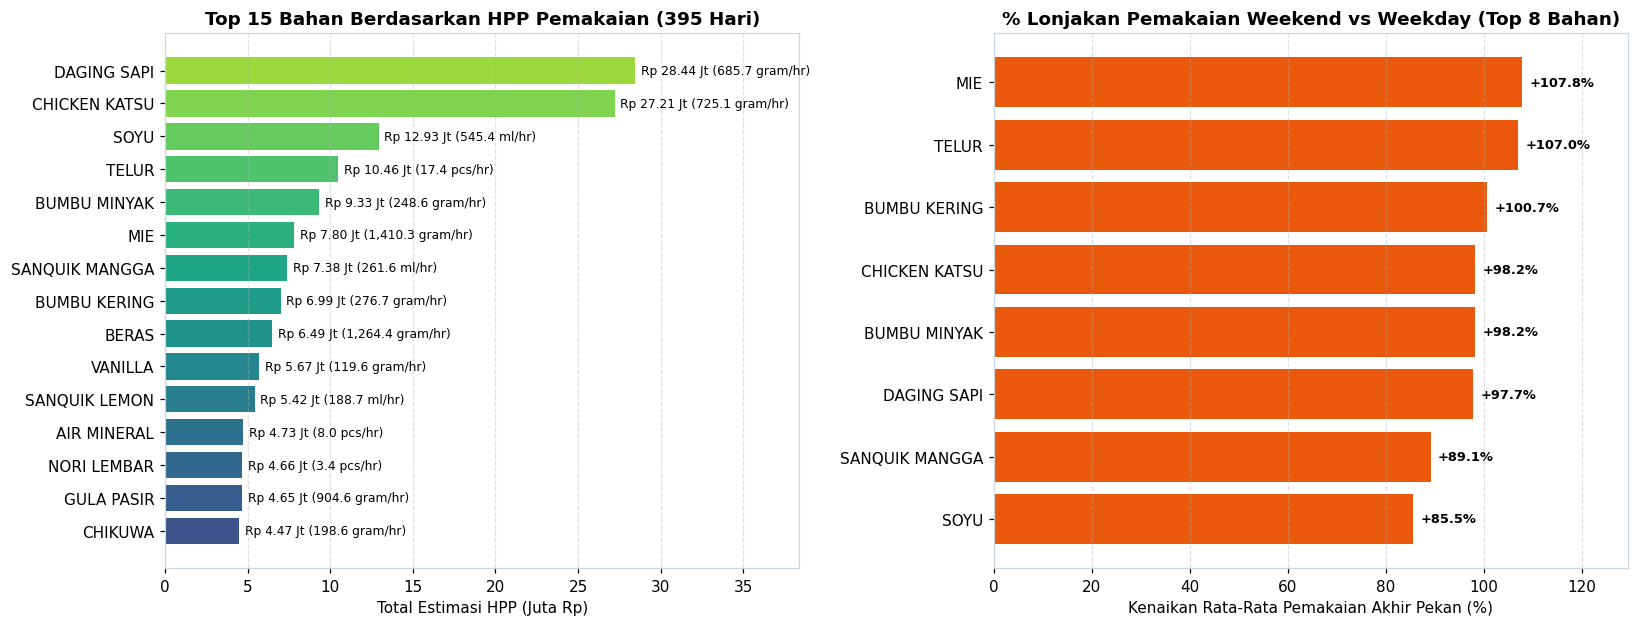

In [8]:
# 1. Dampak order internal vs eksternal pada pemakaian BoM
merged_it = df_items.merge(df_tx[["id_transaksi", "is_internal_order"]], on="id_transaksi", how="left")
merged_bom = merged_it.dropna(subset=["id_menu_resep"]).merge(
    df_bom[["id_menu", "id_bahan", "jumlah_pemakaian", "estimasi_biaya_bahan"]],
    left_on="id_menu_resep", right_on="id_menu", how="inner",
)
merged_bom["used_cost"] = merged_bom["qty"] * merged_bom["estimasi_biaya_bahan"]
cost_split = merged_bom.groupby("is_internal_order")["used_cost"].sum().rename(index={0: "Eksternal", 1: "Internal (Crew/Owner)"})
print("Estimasi Nilai HPP Bahan Baku Terpakai (Eksternal vs Internal):")
for k, v in cost_split.items():
    print(f"  {k:24s}: Rp {v:14,.0f} ({v / cost_split.sum() * 100:.2f}%)")

# 2. Top 15 Bahan Baku (395 Hari Operasional Aktif)
top_ing = (
    df_usage.groupby(["id_bahan", "nama_bahan", "satuan_dasar"], as_index=False)
    .agg(total_pemakaian=("total_pemakaian", "sum"), total_hpp=("estimasi_hpp", "sum"))
    .sort_values("total_hpp", ascending=False)
)
top_ing["burn_rate_395d"] = (top_ing["total_pemakaian"] / 395.0).round(2)
top15 = top_ing.head(15).copy()
print(f"\nBahan aktif terpakai di penjualan: {df_usage['id_bahan'].nunique()} / {len(df_bahan)}")
print("\nTop 15 Bahan Baku Berdasarkan Total HPP Pemakaian:")
print(top15[["nama_bahan", "satuan_dasar", "total_pemakaian", "burn_rate_395d", "total_hpp"]].to_string(index=False))

# 3. Lonjakan pemakaian Weekday vs Weekend untuk Top 8 bahan
df_usage["dow"] = pd.to_datetime(df_usage["tanggal"]).dt.dayofweek
df_usage["is_weekend"] = df_usage["dow"].isin([4, 5, 6])
active_cal = df_tx[["tanggal"]].drop_duplicates().copy()
active_cal["is_weekend"] = pd.to_datetime(active_cal["tanggal"]).dt.dayofweek.isin([4, 5, 6])
n_wkday_days = int((~active_cal["is_weekend"]).sum())
n_wkend_days = int(active_cal["is_weekend"].sum())

top8_names = top15["nama_bahan"].head(8).tolist()
sub8 = df_usage[df_usage["nama_bahan"].isin(top8_names)]
piv8 = sub8.groupby(["nama_bahan", "is_weekend"])["total_pemakaian"].sum().unstack(fill_value=0)
piv8["avg_weekday"] = piv8[False] / n_wkday_days
piv8["avg_weekend"] = piv8[True] / n_wkend_days
piv8["lonjakan_pct"] = ((piv8["avg_weekend"] / piv8["avg_weekday"] - 1) * 100).round(1)
print("\nLonjakan Pemakaian Harian Akhir Pekan (Top 8 Bahan):")
print(piv8[["avg_weekday", "avg_weekend", "lonjakan_pct"]].round(2).to_string())

fig, axes = plt.subplots(1, 2, figsize=(15, 5.8))
p15 = top15.sort_values("total_hpp", ascending=True)
pal = plt.cm.viridis(np.linspace(0.25, 0.85, len(p15)))
b15 = axes[0].barh(p15["nama_bahan"], p15["total_hpp"] / 1e6, color=pal)
axes[0].set_title("Top 15 Bahan Berdasarkan HPP Pemakaian (395 Hari)", fontweight="bold")
axes[0].set_xlabel("Total Estimasi HPP (Juta Rp)")
axes[0].set_xlim(0, (p15["total_hpp"].max() / 1e6) * 1.35)
axes[0].grid(axis="x", linestyle="--", alpha=0.4)
for b, (_, r) in zip(b15, p15.iterrows()):
    axes[0].text(b.get_width() + 0.35, b.get_y() + b.get_height()/2, f"Rp {r['total_hpp']/1e6:.2f} Jt ({r['burn_rate_395d']:,.1f} {r['satuan_dasar']}/hr)", va="center", fontsize=8)

p8 = piv8.sort_values("lonjakan_pct", ascending=True)
b8 = axes[1].barh(p8.index, p8["lonjakan_pct"], color="#EA580C")
axes[1].set_title("% Lonjakan Pemakaian Weekend vs Weekday (Top 8 Bahan)", fontweight="bold")
axes[1].set_xlabel("Kenaikan Rata-Rata Pemakaian Akhir Pekan (%)")
axes[1].set_xlim(0, p8["lonjakan_pct"].max() * 1.2)
axes[1].grid(axis="x", linestyle="--", alpha=0.4)
for b in b8:
    axes[1].text(b.get_width() + 1.5, b.get_y() + b.get_height()/2, f"+{b.get_width():.1f}%", va="center", fontsize=8.5, fontweight="bold")

plt.tight_layout()
plt.show()

### Q&A
1. **Bagaimana pola trafik penjualan per hari, *Weekday* vs *Weekend*, dan jam tersibuk?**  
   Senin–Kamis stabil di `17,8–19,4` tx/hari (`Rp 2,55–2,78 Jt/hari`), Jumat mulai naik ke `20,6` tx/hari (`Rp 3,04 Jt`), lalu memuncak di **Sabtu (`34,1` tx / Rp 6,27 Jt)** dan **Minggu (`37,2` tx / Rp 6,33 Jt)**. Secara agregat, **Weekend (Jumat–Minggu)** mencatat **Rp 5.200.040/hari (`30,61 tx`)**, naik **+95,6% omzet (+67,8% trafik)** dibanding **Weekday (Senin–Kamis)** sebesar **Rp 2.658.250/hari (`18,24 tx`)**. Jam tersibuk terpusat pada pukul **17:00–20:59** (puncak pukul **20:00** dengan **1.374 transaksi**).
2. **Bagaimana tren bulanan dan efek *Payday Window*?**  
   Omzet reguler berada di **Rp 73,2 juta – Rp 140,6 juta/bulan**, namun melonjak tajam pada **Maret 2026** menjadi **Rp 214.614.500** (`1.112` tx, AOV `Rp 192.999`) didorong periode Ramadhan, dan tutup 1 hari pada **21 Maret 2026** (Idul Fitri). Sementara itu, efek tanggal gajian (`Tgl 25–5`: **Rp 3,82 Jt/hari** vs reguler **Rp 3,70 Jt/hari**, atau `+3,3%`) jauh lebih kecil dibanding efek akhir pekan.
3. **Bagaimana distribusi *Channel* penjualan dan *Average Order Value (AOV)*?**  
   **Dine-In** mendominasi (`8.286` tx / `89%`, AOV `Rp 166.002`), diikuti `Takeaway` (`422` tx, AOV `Rp 82.033`), `GrabFood` (`265`, AOV `Rp 99.745`), `ShopeeFood` (`225`, AOV `Rp 123.996`), `GoFood` (`87`, AOV `Rp 108.561`), dan `Event` (`10`, AOV `Rp 568.500`).
4. **Menu apa yang paling laris dan di mana celah data resep saat ini?**  
   Kategori terbesar adalah `Ramen` (`10.354` porsi / `Rp 330,2 Jt`), `Minuman` (`7.640`), dan `Sushi` (`4.738` porsi / `Rp 144,8 Jt`). Top menu dipimpin `Redhot Beef Ramen` (`2.331` porsi), `Takoyaki Isi 6` (`1.956`), dan `Le Mineral / Air Mineral` (`1.955`). Namun **41,0% porsi terjual** (termasuk `Sushi Aburi Salmon Mentai` `809` porsi / `Rp 34,08 Jt`) belum ada di resep 2018.
5. **Bahan baku apa yang paling kritis dipantau & bagaimana dampak order internal?**  
   Dari `123` bahan aktif terukur, biaya terbesar terserap pada `DAGING SAPI` (`685,72 g/hr` | Rp 28,44 Jt), `CHICKEN KATSU` (`725,11 g/hr` | Rp 27,21 Jt), dan `SOYU` (`545,42 ml/hr` | Rp 12,93 Jt). Pada akhir pekan, konsumsi melonjak tajam hingga **+107,8% pada `MIE`** (`965,0 g` $\rightarrow$ `2.005,7 g/hr`) dan **+107,0% pada `TELUR`**. Order internal (`787` transaksi `CREW`/`OWNER`) memakan bahan senilai **Rp 5.827.129 (`2,10%` HPP BoM)** sehingga wajib tetap memotong stok.

### Data Analysis Key Findings
- **9.295 transaksi** (`8.508` eksternal + `787` internal) menghasilkan total `grand_total` **Rp 1.479.571.300** (`58.102` porsi net) tanpa missing value pada kolom kunci.
- Faktor penentu lonjakan beban dapur paling ekstrem adalah **Sabtu–Minggu (`> 2x` rata-rata Senin–Kamis)** dan **periode Ramadhan (Maret 2026)**, bukan tanggal gajian.
- Master `dim_bahan_baku` memuat **178 bahan** (`164` bahan pangan, `14` kemasan/utilitas; terstandarisasi ke `117` `gram`, `34` `pcs`, `27` `ml`), didominasi vendor `TOKO HAI & FEI` (`75` bahan) dan `SAYUR` (`31` bahan), dengan menu HPP termahal `HP Nasi Blackpepper Sapi` (`Rp 16.685,51/porsi`).

### Insights or Next Steps
- Gunakan **burn rate khusus akhir pekan (`Jumat–Minggu`)** serta buffer tambahan untuk `MIE`, `TELUR`, `DAGING SAPI`, `CHICKEN KATSU`, dan `BUMBU` agar stok tidak habis sebelum Minggu malam.
- Prioritaskan melengkapi resep kategori **Sushi**, varian **Ramen baru**, dan **Juice** bersama Owner untuk menutup **36,8% `UNMAPPED_FNB`** sehingga kontrol stok mencakup ~80% volume kasir.